In [20]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [21]:
mbb = yf.download("1155.KL", period="10y")["Close"]["1155.KL"]
mbb_returns = mbb.pct_change(fill_method=None).dropna()

[*********************100%***********************]  1 of 1 completed


In [22]:
mu = mbb_returns.mean()
sigma = mbb_returns.std()
S0 = mbb.iloc[-1]

print(f"Mean Daily Return : {mu:.4f}")
print(f"Daily Volatility  : {mbb_returns.std():.4f}")
print(f"Last Price        : {S0:.2f} MYR")

Mean Daily Return : 0.0004
Daily Volatility  : 0.0091
Last Price        : 11.06 MYR


In [23]:
T = 1
n_days = 252
dt = T/n_days

n_simulations = 50000

monte_carlo = []

for i in range(n_simulations):
    prices = [S0]

    for day in range(n_days):
        drift = (mu - sigma ** 2 / 2) * dt
        random = sigma * np.random.normal(0,1) * np.sqrt(dt)

        gbm = prices[-1] * np.exp(drift + random)

        prices.append(gbm)

    monte_carlo.append(prices)


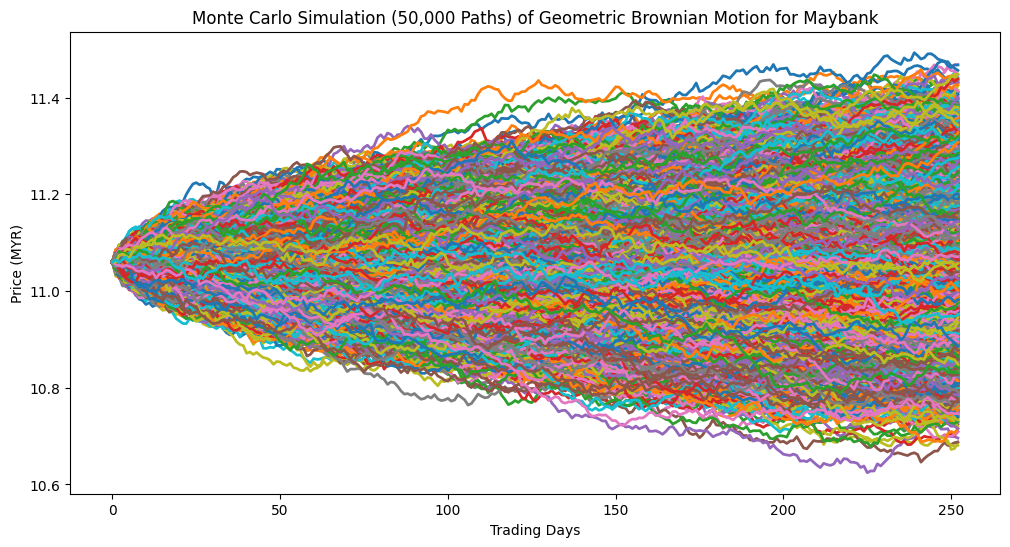

In [27]:
plt.figure(figsize=(12,6))
for path in monte_carlo:
    plt.plot(path, linewidth = 2.0)

plt.title("Monte Carlo Simulation (50,000 Paths) of Geometric Brownian Motion for Maybank")  
plt.xlabel("Trading Days")
plt.ylabel("Price (MYR)")

plt.show()

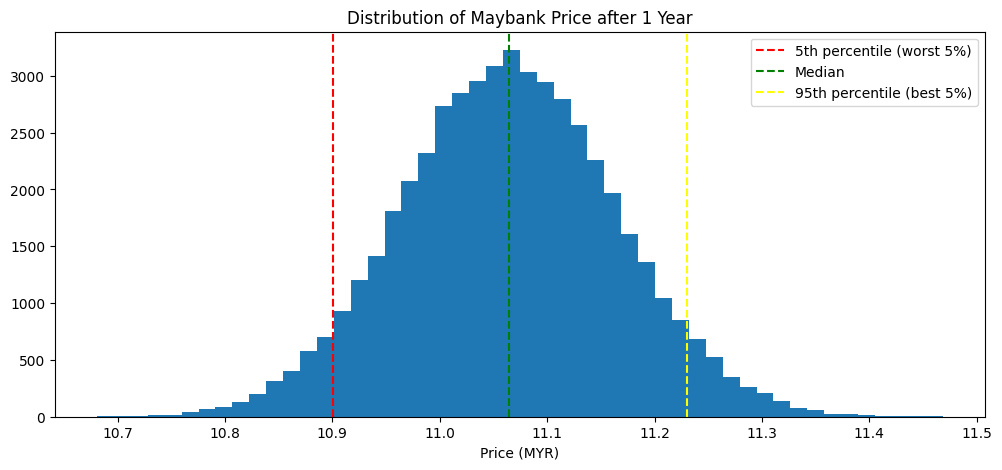

In [ ]:
final_prices = [path[-1] for path in monte_carlo]

plt.figure(figsize=(12,5))
plt.hist(final_prices, bins=50)

plt.axvline(np.percentile(final_prices, 5), color="red", linestyle="--", label="5th percentile (worst 5%)")
plt.axvline(np.percentile(final_prices, 50), color="green", linestyle="--", label="Median")
plt.axvline(np.percentile(final_prices, 95), color="yellow", linestyle="--", label="95th percentile (best 5%)")
plt.legend()

plt.title("Distribution of Maybank Price after 1 Year")
plt.xlabel("Price (MYR)")

plt.show()

In [29]:
final_prices = [path[-1] for path in monte_carlo]
final_prices = np.array(final_prices)

prob_loss = np.mean(final_prices < S0) * 100

print(f"Starting Price      : {S0:.2f} MYR")
print(f"Worst Case  (5%)    : {np.percentile(final_prices, 5):.2f} MYR")
print(f"Median      (50%)   : {np.percentile(final_prices, 50):.2f} MYR")
print(f"Best Case   (95%)   : {np.percentile(final_prices, 95):.2f} MYR")
print(f"Average Final Price : {np.mean(final_prices):.2f} MYR")
print(f"Probability Loss    : {prob_loss:.2f}%")

Starting Price      : 11.06 MYR
Worst Case  (5%)    : 10.90 MYR
Median      (50%)   : 11.06 MYR
Best Case   (95%)   : 11.23 MYR
Average Final Price : 11.06 MYR
Probability Loss    : 48.31%
